# RQ1 Step 4: Fully Connected Neural Network trajectory model

This notebook uses the same 98 inputs, 144 targets and fixed partitions as Ridge, but adds nonlinear hidden layers. The neural network, backpropagation and Adam optimiser are implemented in NumPy so the notebook has no additional deep-learning dependency.


## 1. Model definition

The candidate FNNs map 98 standardised inputs through ReLU hidden layers to 144 unconstrained displacement outputs. Training minimises standardised target MSE plus L2 weight regularisation.


In [1]:
from pathlib import Path
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find data/processed; open the notebook from the project directory or a notebook subdirectory.')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'en'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6_371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
N_FOLDS = 5
RANDOM_SEED = 3001

# Limit training time and reduce overfitting risk.
MAX_EPOCHS = 180
PATIENCE = 20
BATCH_SIZE = 256
LEARNING_RATE = 1e-3

# A small candidate set compares network capacity and L2 strength.
FNN_CONFIGS = [
    {'name': '64', 'hidden_sizes': (64,), 'l2': 1e-4},
    {'name': '128-64', 'hidden_sizes': (128, 64), 'l2': 1e-4},
    {'name': '128-64 stronger L2', 'hidden_sizes': (128, 64), 'l2': 1e-3},
]

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Project directory: ', PROJECT_ROOT.resolve())
print('Output directory: ', OUTPUT_DIR.resolve())

Project directory:  /Users/roger/Documents/data3001-project-main
Output directory:  /Users/roger/Documents/data3001-project-main/output/rq1/en


## 2. Convert spherical positions and local displacements

The network predicts east/north displacement relative to the forecast origin. Predictions are converted back to latitude/longitude for Haversine evaluation.


In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0
    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central_angle = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance_km = EARTH_RADIUS_KM * central_angle
    return distance_km * np.sin(bearing), distance_km * np.cos(bearing)


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east_km = np.asarray(east_km, dtype=float)
    north_km = np.asarray(north_km, dtype=float)
    distance_km = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular_distance = distance_km / EARTH_RADIUS_KM
    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular_distance)
        + np.cos(lat0) * np.sin(angular_distance) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance) * np.cos(lat0),
        np.cos(angular_distance) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180.0) % 360.0 - 180.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

## 3. Read fixed cases and construct 98 inputs

The input contains origin location and 24 hourly values of relative position and velocity. It is identical to the Ridge input, enabling a controlled linear-versus-nonlinear comparison.


In [3]:
origins = (
    pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
    .sort_values('forecast_case_id').reset_index(drop=True)
)
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude', 've', 'vn'],
)
n_cases = len(origins)

history = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'history_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history['history_index'] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history['segment_step'] = history['history_start_step'] + history['history_index']
history = history.merge(
    observations, on=['ID', 'segment_id', 'segment_step'],
    how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'history_index']).reset_index(drop=True)

history['relative_east_km'], history['relative_north_km'] = latlon_to_local_km(
    history['origin_latitude'], history['origin_longitude'],
    history['latitude'], history['longitude'],
)
history_values = history[[
    'relative_east_km', 'relative_north_km', 've', 'vn',
]].to_numpy().reshape(n_cases, HISTORY_HOURS, 4)

X = np.column_stack([
    origins['origin_latitude'].to_numpy(),
    origins['origin_longitude'].to_numpy(),
    history_values.reshape(n_cases, -1),
]).astype(np.float64)

history_checks = pd.Series({
    'There are 5,117 cases': n_cases == 5117,
    'Every case has exactly 24 historical observations': history.groupby('forecast_case_id').size().eq(24).all(),
    'Input matrix has shape 5117 x 98': X.shape == (5117, 98),
    'Inputs contain no missing or infinite values': np.isfinite(X).all(),
}, name='Passed')
display(history_checks.to_frame())
assert history_checks.all()

,Passed
"There are 5,117 cases",True
Every case has exactly 24 historical observations,True
Input matrix has shape 5117 x 98,True
Inputs contain no missing or infinite values,True


## 4. Construct 144 future targets

The 72 observed future positions are converted into east/north displacement pairs relative to the forecast origin.


In [4]:
targets = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'target_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets['lead_time_hours'] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets['segment_step'] = targets['target_start_step'] + targets['lead_time_hours'] - 1
targets = targets.merge(
    observations[['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude']],
    on=['ID', 'segment_id', 'segment_step'], how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'lead_time_hours']).reset_index(drop=True)

targets['target_east_km'], targets['target_north_km'] = latlon_to_local_km(
    targets['origin_latitude'], targets['origin_longitude'],
    targets['latitude'], targets['longitude'],
)
Y = targets[['target_east_km', 'target_north_km']].to_numpy().reshape(
    n_cases, HORIZON_HOURS * 2
).astype(np.float64)

target_checks = pd.Series({
    'Every case has exactly 72 future observations': targets.groupby('forecast_case_id').size().eq(72).all(),
    'Target matrix has shape 5117 x 144': Y.shape == (5117, 144),
    'Targets contain no missing or infinite values': np.isfinite(Y).all(),
}, name='Passed')
display(target_checks.to_frame())
assert target_checks.all()

,Passed
Every case has exactly 72 future observations,True
Target matrix has shape 5117 x 144,True
Targets contain no missing or infinite values,True


## 5. Grouped five-fold cross-validation within training drifters

Cases from one drifter remain together. Calibration and test data are excluded from architecture, regularisation and epoch selection.


In [5]:
train_indices = np.flatnonzero(origins['partition'].eq('training').to_numpy())
calibration_indices = np.flatnonzero(origins['partition'].eq('calibration').to_numpy())
test_indices = np.flatnonzero(origins['partition'].eq('test').to_numpy())

training_group_counts = origins.loc[train_indices].groupby('ID').size().sort_values(ascending=False)
fold_drifters = [[] for _ in range(N_FOLDS)]
fold_case_counts = np.zeros(N_FOLDS, dtype=int)
for drifter_id, count in training_group_counts.items():
    fold = int(np.argmin(fold_case_counts))
    fold_drifters[fold].append(drifter_id)
    fold_case_counts[fold] += int(count)

fold_summary = pd.DataFrame({
    'Fold': np.arange(1, N_FOLDS + 1),
    'Training drifters held out': [len(x) for x in fold_drifters],
    'Validation cases': fold_case_counts,
})
display(fold_summary)

assert len(train_indices) == 3591
assert len(calibration_indices) == 769
assert len(test_indices) == 757
assert fold_case_counts.sum() == len(train_indices)

,Fold,Training drifters held out,Validation cases
0,1,63,719
1,2,62,718
2,3,62,718
3,4,62,718
4,5,62,718


## 6. NumPy FNN and Adam optimiser

This section implements He initialisation, ReLU forward propagation, analytical backpropagation, Adam updates and early stopping. Inputs and targets are standardised from the active training fold only.


In [6]:
def relu(x):
    return np.maximum(x, 0.0)


def initialise_parameters(layer_sizes, rng):
    parameters = []
    for fan_in, fan_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        # Use He initialisation for ReLU hidden layers and a stable small scale for the output layer.
        scale = np.sqrt(2.0 / fan_in)
        parameters.append({
            'W': rng.normal(0.0, scale, size=(fan_in, fan_out)),
            'b': np.zeros(fan_out),
        })
    return parameters


def forward(parameters, X_batch):
    activations = [X_batch]
    pre_activations = []
    current = X_batch
    for layer_number, layer in enumerate(parameters):
        z = current @ layer['W'] + layer['b']
        pre_activations.append(z)
        current = relu(z) if layer_number < len(parameters) - 1 else z
        activations.append(current)
    return current, activations, pre_activations


def loss_and_gradients(parameters, X_batch, Y_batch, l2):
    prediction, activations, pre_activations = forward(parameters, X_batch)
    residual = prediction - Y_batch
    mse = np.mean(np.square(residual))
    penalty = l2 * sum(np.sum(np.square(layer['W'])) for layer in parameters)

    delta = 2.0 * residual / residual.size
    gradients = [None] * len(parameters)
    for layer_number in range(len(parameters) - 1, -1, -1):
        gradients[layer_number] = {
            'W': activations[layer_number].T @ delta + 2.0 * l2 * parameters[layer_number]['W'],
            'b': delta.sum(axis=0),
        }
        if layer_number > 0:
            delta = (delta @ parameters[layer_number]['W'].T) * (
                pre_activations[layer_number - 1] > 0
            )
    return mse + penalty, gradients


def predict_standardised(parameters, X_standard):
    return forward(parameters, X_standard)[0]


def fit_fnn(X_train, Y_train, X_valid, Y_valid, hidden_sizes, l2, seed,
            max_epochs=MAX_EPOCHS, patience=PATIENCE, verbose=False):
    x_mean = X_train.mean(axis=0)
    x_scale = X_train.std(axis=0)
    x_scale[x_scale < 1e-12] = 1.0
    y_mean = Y_train.mean(axis=0)
    y_scale = Y_train.std(axis=0)
    y_scale[y_scale < 1e-12] = 1.0

    Xtr = (X_train - x_mean) / x_scale
    Ytr = (Y_train - y_mean) / y_scale
    Xva = (X_valid - x_mean) / x_scale

    rng = np.random.default_rng(seed)
    parameters = initialise_parameters((X.shape[1], *hidden_sizes, Y.shape[1]), rng)
    first_moment = [
        {'W': np.zeros_like(p['W']), 'b': np.zeros_like(p['b'])} for p in parameters
    ]
    second_moment = copy.deepcopy(first_moment)
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    step = 0
    best_rmse = np.inf
    best_parameters = None
    best_epoch = 0
    epochs_without_improvement = 0
    history_rows = []

    for epoch in range(1, max_epochs + 1):
        permutation = rng.permutation(len(Xtr))
        batch_losses = []
        for start in range(0, len(Xtr), BATCH_SIZE):
            batch = permutation[start:start + BATCH_SIZE]
            loss, gradients = loss_and_gradients(parameters, Xtr[batch], Ytr[batch], l2)
            batch_losses.append(loss)
            step += 1
            for layer_number, (layer, gradient) in enumerate(zip(parameters, gradients)):
                for key in ('W', 'b'):
                    first_moment[layer_number][key] = (
                        beta1 * first_moment[layer_number][key] + (1 - beta1) * gradient[key]
                    )
                    second_moment[layer_number][key] = (
                        beta2 * second_moment[layer_number][key] + (1 - beta2) * np.square(gradient[key])
                    )
                    m_hat = first_moment[layer_number][key] / (1 - beta1 ** step)
                    v_hat = second_moment[layer_number][key] / (1 - beta2 ** step)
                    layer[key] -= LEARNING_RATE * m_hat / (np.sqrt(v_hat) + epsilon)

        valid_standard = predict_standardised(parameters, Xva)
        valid_prediction = valid_standard * y_scale + y_mean
        valid_rmse = float(np.sqrt(np.mean(np.square(valid_prediction - Y_valid))))
        history_rows.append({
            'epoch': epoch,
            'training_objective': float(np.mean(batch_losses)),
            'validation_displacement_rmse_km': valid_rmse,
        })

        if valid_rmse < best_rmse - 1e-5:
            best_rmse = valid_rmse
            best_epoch = epoch
            best_parameters = copy.deepcopy(parameters)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose and (epoch == 1 or epoch % 25 == 0):
            print(f'epoch={epoch:3d}, validation RMSE={valid_rmse:.3f} km')
        if epochs_without_improvement >= patience:
            break

    return {
        'hidden_sizes': tuple(hidden_sizes), 'l2': float(l2),
        'x_mean': x_mean, 'x_scale': x_scale,
        'y_mean': y_mean, 'y_scale': y_scale,
        'parameters': best_parameters, 'best_epoch': best_epoch,
        'best_validation_rmse_km': best_rmse,
        'history': pd.DataFrame(history_rows),
    }


def predict_fnn(model, X_new):
    X_standard = (X_new - model['x_mean']) / model['x_scale']
    prediction_standard = predict_standardised(model['parameters'], X_standard)
    return prediction_standard * model['y_scale'] + model['y_mean']

## 7. Select the network configuration within training data

Three prespecified capacity/regularisation configurations are compared on the same five grouped folds. Mean validation displacement RMSE selects the final configuration; the median best epoch determines final training duration.


In [7]:
cv_rows = []
cv_histories = []
training_start = time.time()

for config_number, config in enumerate(FNN_CONFIGS):
    print(f"\nConfiguration {config['name']}, hidden={config['hidden_sizes']}, L2={config['l2']:g}")
    for fold_number, validation_drifters in enumerate(fold_drifters, start=1):
        is_validation = origins.loc[train_indices, 'ID'].isin(validation_drifters).to_numpy()
        fold_validation_indices = train_indices[is_validation]
        fold_training_indices = train_indices[~is_validation]
        model = fit_fnn(
            X[fold_training_indices], Y[fold_training_indices],
            X[fold_validation_indices], Y[fold_validation_indices],
            hidden_sizes=config['hidden_sizes'], l2=config['l2'],
            seed=RANDOM_SEED + 100 * config_number + fold_number,
        )
        cv_rows.append({
            'config': config['name'],
            'hidden_sizes': str(config['hidden_sizes']),
            'l2': config['l2'],
            'fold': fold_number,
            'validation_cases': len(fold_validation_indices),
            'best_epoch': model['best_epoch'],
            'validation_displacement_rmse_km': model['best_validation_rmse_km'],
        })
        fold_history = model['history'].copy()
        fold_history['config'] = config['name']
        fold_history['fold'] = fold_number
        cv_histories.append(fold_history)
        print(
            f"  Fold {fold_number}: epoch {model['best_epoch']}, "
            f"validation RMSE={model['best_validation_rmse_km']:.3f} km"
        )

cv_folds = pd.DataFrame(cv_rows)
cv_history = pd.concat(cv_histories, ignore_index=True)
cv_results = (
    cv_folds.groupby(['config', 'hidden_sizes', 'l2'], sort=False)
    .agg(
        mean_cv_rmse_km=('validation_displacement_rmse_km', 'mean'),
        std_cv_rmse_km=('validation_displacement_rmse_km', 'std'),
        median_best_epoch=('best_epoch', 'median'),
    )
    .reset_index()
)
best_row = cv_results.loc[cv_results['mean_cv_rmse_km'].idxmin()]
best_config = next(c for c in FNN_CONFIGS if c['name'] == best_row['config'])
selected_epochs = int(round(best_row['median_best_epoch']))

display(cv_results.round(3))
print('Selected configuration: ', best_config)
print('Final epochs (median best epoch across folds): ', selected_epochs)
print(f'Cross-validation time: {time.time() - training_start:.1f} seconds')


Configuration 64, hidden=(64,), L2=0.0001


  Fold 1: epoch 175, validation RMSE=26.845 km


  Fold 2: epoch 147, validation RMSE=26.915 km


  Fold 3: epoch 176, validation RMSE=26.405 km


  Fold 4: epoch 180, validation RMSE=28.858 km


  Fold 5: epoch 174, validation RMSE=25.883 km

Configuration 128-64, hidden=(128, 64), L2=0.0001


... (8 outputs left out)

  Fold 4: epoch 111, validation RMSE=28.659 km


  Fold 5: epoch 132, validation RMSE=25.098 km


,config,hidden_sizes,l2,mean_cv_rmse_km,std_cv_rmse_km,median_best_epoch
0,64,"(64,)",0.000,26.981,1.127,175.0
1,128-64,"(128, 64)",0.000,26.710,1.265,87.0
2,128-64 stronger L2,"(128, 64)",0.001,26.399,1.342,129.0


Selected configuration:  {'name': '128-64 stronger L2', 'hidden_sizes': (128, 64), 'l2': 0.001}
Final epochs (median best epoch across folds):  129
Cross-validation time: 15.4 seconds


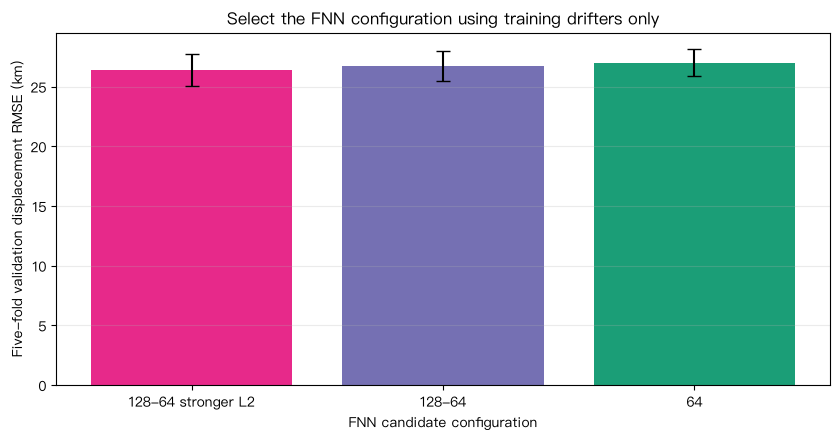

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_data = cv_results.sort_values('mean_cv_rmse_km')
ax.bar(
    plot_data['config'], plot_data['mean_cv_rmse_km'],
    yerr=plot_data['std_cv_rmse_km'], capsize=5, color=['#e7298a', '#7570b3', '#1b9e77'],
)
ax.set(
    xlabel='FNN candidate configuration', ylabel='Five-fold validation displacement RMSE (km)',
    title='Select the FNN configuration using training drifters only',
)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fnn_cross_validation.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Fit the final FNN on all training cases

The selected architecture is trained for the fixed number of epochs on all 3,591 training cases, then frozen before test prediction.


In [9]:
def fit_final_fnn(X_train, Y_train, hidden_sizes, l2, epochs, seed):
    x_mean = X_train.mean(axis=0)
    x_scale = X_train.std(axis=0)
    x_scale[x_scale < 1e-12] = 1.0
    y_mean = Y_train.mean(axis=0)
    y_scale = Y_train.std(axis=0)
    y_scale[y_scale < 1e-12] = 1.0
    Xtr = (X_train - x_mean) / x_scale
    Ytr = (Y_train - y_mean) / y_scale

    rng = np.random.default_rng(seed)
    parameters = initialise_parameters((X.shape[1], *hidden_sizes, Y.shape[1]), rng)
    first_moment = [{'W': np.zeros_like(p['W']), 'b': np.zeros_like(p['b'])} for p in parameters]
    second_moment = copy.deepcopy(first_moment)
    beta1, beta2, epsilon = 0.9, 0.999, 1e-8
    step = 0
    training_losses = []

    for epoch in range(1, epochs + 1):
        permutation = rng.permutation(len(Xtr))
        epoch_losses = []
        for start in range(0, len(Xtr), BATCH_SIZE):
            batch = permutation[start:start + BATCH_SIZE]
            loss, gradients = loss_and_gradients(parameters, Xtr[batch], Ytr[batch], l2)
            epoch_losses.append(loss)
            step += 1
            for layer_number, (layer, gradient) in enumerate(zip(parameters, gradients)):
                for key in ('W', 'b'):
                    first_moment[layer_number][key] = beta1 * first_moment[layer_number][key] + (1-beta1) * gradient[key]
                    second_moment[layer_number][key] = beta2 * second_moment[layer_number][key] + (1-beta2) * np.square(gradient[key])
                    m_hat = first_moment[layer_number][key] / (1-beta1**step)
                    v_hat = second_moment[layer_number][key] / (1-beta2**step)
                    layer[key] -= LEARNING_RATE * m_hat / (np.sqrt(v_hat) + epsilon)
        training_losses.append(float(np.mean(epoch_losses)))

    return {
        'hidden_sizes': tuple(hidden_sizes), 'l2': float(l2), 'epochs': int(epochs),
        'x_mean': x_mean, 'x_scale': x_scale, 'y_mean': y_mean, 'y_scale': y_scale,
        'parameters': parameters, 'training_losses': np.array(training_losses),
    }


final_model = fit_final_fnn(
    X[train_indices], Y[train_indices],
    hidden_sizes=best_config['hidden_sizes'], l2=best_config['l2'],
    epochs=selected_epochs, seed=RANDOM_SEED + 999,
)
test_predictions = predict_fnn(final_model, X[test_indices]).reshape(
    len(test_indices), HORIZON_HOURS, 2
)
print('Final network: ', final_model['hidden_sizes'])
print('Final training epochs: ', final_model['epochs'])
print('Test prediction array: ', test_predictions.shape)

Final network:  (128, 64)
Final training epochs:  129
Test prediction array:  (757, 72, 2)


## 9. Convert predictions and calculate held-out error

Predicted displacements are converted to geographic coordinates and evaluated on the same 757 test cases. Calibration remains unused.


In [10]:
test_origins = origins.loc[test_indices].reset_index(drop=True)
origin_latitudes = np.repeat(test_origins['origin_latitude'].to_numpy(), HORIZON_HOURS)
origin_longitudes = np.repeat(test_origins['origin_longitude'].to_numpy(), HORIZON_HOURS)
predicted_latitude, predicted_longitude = local_km_to_latlon(
    origin_latitudes, origin_longitudes,
    test_predictions[:, :, 0].reshape(-1),
    test_predictions[:, :, 1].reshape(-1),
)

test_target_mask = targets['forecast_case_id'].isin(test_origins['forecast_case_id'])
test_targets = targets.loc[test_target_mask].sort_values(
    ['forecast_case_id', 'lead_time_hours']
).reset_index(drop=True)

evaluation = pd.DataFrame({
    'forecast_case_id': np.repeat(test_origins['forecast_case_id'].to_numpy(), HORIZON_HOURS),
    'ID': np.repeat(test_origins['ID'].to_numpy(), HORIZON_HOURS),
    'lead_time_hours': np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
    'origin_latitude': origin_latitudes,
    'origin_longitude': origin_longitudes,
    'predicted_east_km': test_predictions[:, :, 0].reshape(-1),
    'predicted_north_km': test_predictions[:, :, 1].reshape(-1),
    'pred_latitude': predicted_latitude,
    'pred_longitude': predicted_longitude,
    'true_latitude': test_targets['latitude'].to_numpy(),
    'true_longitude': test_targets['longitude'].to_numpy(),
})
evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)

checks = pd.Series({
    'Evaluate only 757 test cases': evaluation['forecast_case_id'].nunique() == 757,
    'Every test case has exactly 72 lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
    'All errors are finite': np.isfinite(evaluation['separation_error_km']).all(),
    'Calibration cases remain unused for fitting': len(calibration_indices) == 769,
}, name='Passed')
display(checks.to_frame())
assert checks.all()

,Passed
Evaluate only 757 test cases,True
Every test case has exactly 72 lead times,True
All errors are finite,True
Calibration cases remain unused for fitting,True


## 10. Held-out test error by lead time

The curve reports median separation error and the middle 50% of test cases at every forecast hour.


,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,0.34,0.45,0.20,0.56,0.61
5,6,757,2.67,3.22,1.59,4.13,3.99
11,12,757,5.54,6.91,3.36,9.03,8.71
23,24,757,11.32,14.36,6.52,18.79,18.15
47,48,757,26.10,32.09,14.59,42.59,40.21
71,72,757,41.72,50.12,23.06,66.21,62.15


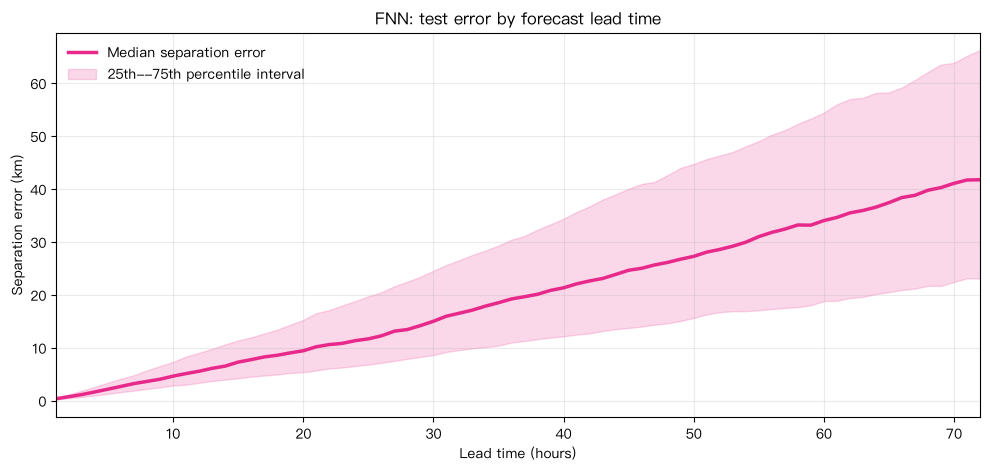

In [11]:
lead_metrics = (
    evaluation.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size', median_error_km='median', mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    ).reset_index()
)
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#e7298a', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#e7298a', alpha=0.18, label='25th--75th percentile interval')
ax.set(
    xlabel='Lead time (hours)', ylabel='Separation error (km)',
    title='FNN: test error by forecast lead time',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fnn_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 11. Fair comparison with Ridge and both baselines

All methods use identical cases and metrics. RMSE differences and forecast skill quantify the nonlinear model's improvement.


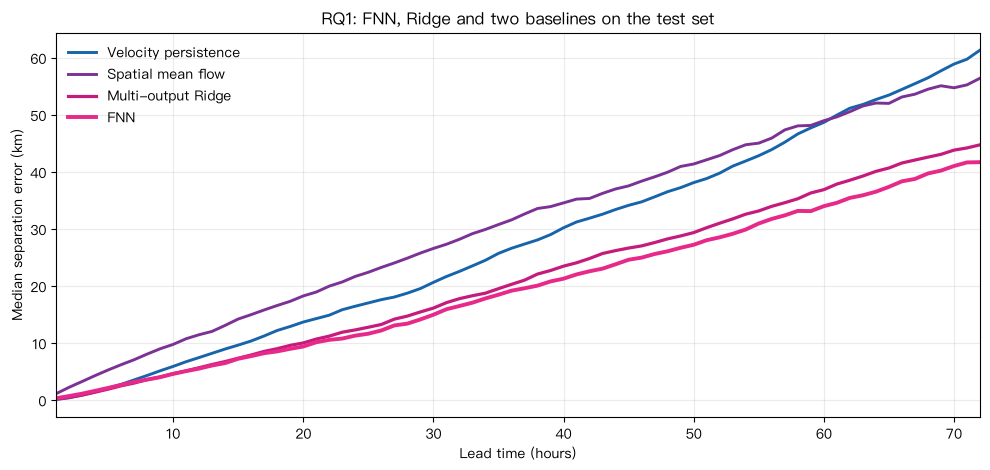

,fnn_median_km,ridge_median_km,persistence_median_km,mean_flow_median_km,fnn_rmse_km,ridge_rmse_km,persistence_rmse_km,mean_flow_rmse_km,fnn_rmse_minus_ridge_km,skill_vs_ridge_pct,skill_vs_persistence_pct,skill_vs_mean_flow_pct
lead_time_hours,,,,,,,,,,,,
24,11.32,12.32,16.47,21.69,18.15,18.97,24.07,29.87,-0.82,4.32,24.57,39.22
48,26.10,28.27,36.54,39.96,40.21,42.59,55.17,57.27,-2.38,5.58,27.12,29.79
72,41.72,44.75,61.35,56.42,62.15,65.91,90.10,80.98,-3.76,5.71,31.02,23.25


In [12]:
persistence_metrics = pd.read_csv(OUTPUT_DIR / 'velocity_persistence_lead_metrics.csv')
mean_flow_metrics = pd.read_csv(OUTPUT_DIR / 'spatial_mean_flow_lead_metrics.csv')
ridge_metrics = pd.read_csv(OUTPUT_DIR / 'ridge_lead_metrics.csv')

comparison = lead_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
    'median_error_km': 'fnn_median_km', 'rmse_km': 'fnn_rmse_km',
})
for name, frame in [
    ('persistence', persistence_metrics), ('mean_flow', mean_flow_metrics), ('ridge', ridge_metrics),
]:
    comparison = comparison.merge(
        frame[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': f'{name}_median_km', 'rmse_km': f'{name}_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
    comparison[f'fnn_rmse_minus_{name}_km'] = comparison['fnn_rmse_km'] - comparison[f'{name}_rmse_km']
    comparison[f'skill_vs_{name}_pct'] = 100 * (1 - comparison['fnn_rmse_km'] / comparison[f'{name}_rmse_km'])

fig, ax = plt.subplots(figsize=(10, 4.8))
for column, label, color, width in [
    ('persistence_median_km', 'Velocity persistence', '#1764ab', 2.1),
    ('mean_flow_median_km', 'Spatial mean flow', '#7b3294', 2.1),
    ('ridge_median_km', 'Multi-output Ridge', '#c51b7d', 2.3),
    ('fnn_median_km', 'FNN', '#e7298a', 2.8),
]:
    ax.plot(comparison['lead_time_hours'], comparison[column], linewidth=width, color=color, label=label)
ax.set(
    xlabel='Lead time (hours)', ylabel='Median separation error (km)',
    title='RQ1: FNN, Ridge and two baselines on the test set',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'rq1_four_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

comparison_table = comparison.loc[
    comparison['lead_time_hours'].isin([24, 48, 72]),
    [
        'lead_time_hours', 'fnn_median_km', 'ridge_median_km',
        'persistence_median_km', 'mean_flow_median_km',
        'fnn_rmse_km', 'ridge_rmse_km', 'persistence_rmse_km', 'mean_flow_rmse_km',
        'fnn_rmse_minus_ridge_km', 'skill_vs_ridge_pct',
        'skill_vs_persistence_pct', 'skill_vs_mean_flow_pct',
    ],
].set_index('lead_time_hours')
display(comparison_table.round(2))

## 12. Case-level integrated trajectory error and final summary

ITE measures accumulated error over the whole trajectory; headline values report 24-, 48- and 72-hour performance.


In [13]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = evaluation.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    'Metric': [
        'Selected configuration', 'Selected L2', 'Selected epochs',
        'Training cases', 'Calibration cases (unused)', 'Test cases',
        '24h median error (km)', '48h median error (km)', '72h median error (km)',
        '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    'Value': [
        best_config['name'], best_config['l2'], selected_epochs,
        len(train_indices), len(calibration_indices), len(test_indices),
        metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary)

,Metric,Value
0,Selected configuration,128-64 stronger L2
1,Selected L2,0.001
2,Selected epochs,129
3,Training cases,3591
4,Calibration cases (unused),769
5,Test cases,757
6,24h median error (km),11.316341
7,48h median error (km),26.102218
8,72h median error (km),41.715535
9,72h RMSE (km),62.149823


## 13. Representative test trajectory

The example has a 72-hour error closest to the FNN test median.


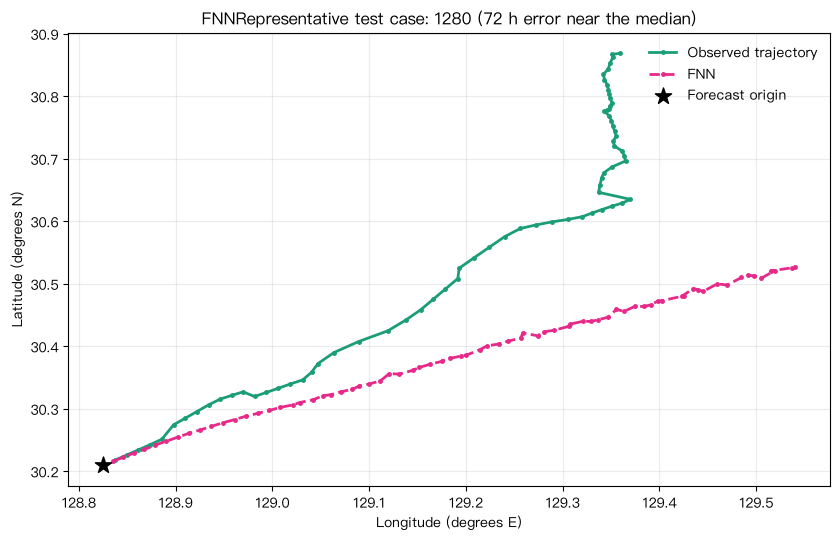

In [14]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example = evaluation[evaluation['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
        linewidth=2, color='#1b9e77', label='Observed trajectory')
ax.plot(example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
        linewidth=2, color='#e7298a', label='FNN')
ax.scatter(example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
           marker='*', s=150, color='black', label='Forecast origin', zorder=5)
ax.set(
    xlabel='Longitude (degrees E)', ylabel='Latitude (degrees N)',
    title=f'FNNRepresentative test case: {int(example_id)} (72 h error near the median)',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'fnn_example_trajectory.png', dpi=200, bbox_inches='tight')
plt.show()

## 14. Save reproducible results

Save cross-validation histories, fitted parameters, held-out metrics, comparisons and figures.


In [15]:
cv_folds.to_csv(OUTPUT_DIR / 'fnn_cross_validation_folds.csv', index=False)
cv_results.to_csv(OUTPUT_DIR / 'fnn_cross_validation_summary.csv', index=False)
cv_history.to_csv(OUTPUT_DIR / 'fnn_training_histories.csv', index=False)
lead_metrics.to_csv(OUTPUT_DIR / 'fnn_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'fnn_test_case_metrics.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'rq1_four_model_comparison.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'fnn_summary.csv', index=False)

parameter_archive = {
    'hidden_sizes': np.array(final_model['hidden_sizes']),
    'l2': np.array(final_model['l2']),
    'epochs': np.array(final_model['epochs']),
    'x_mean': final_model['x_mean'], 'x_scale': final_model['x_scale'],
    'y_mean': final_model['y_mean'], 'y_scale': final_model['y_scale'],
}
for layer_number, layer in enumerate(final_model['parameters'], start=1):
    parameter_archive[f'W{layer_number}'] = layer['W']
    parameter_archive[f'b{layer_number}'] = layer['b']
np.savez_compressed(OUTPUT_DIR / 'fnn_model_parameters.npz', **parameter_archive)

saved_files = sorted(
    [p.name for p in OUTPUT_DIR.glob('fnn_*')]
    + [p.name for p in OUTPUT_DIR.glob('rq1_four_model_*')]
)
print('Saved:')
for name in saved_files:
    print(' -', name)

Saved:
 - fnn_cross_validation.png
 - fnn_cross_validation_folds.csv
 - fnn_cross_validation_summary.csv
 - fnn_error_curve.png
 - fnn_example_trajectory.png
 - fnn_lead_metrics.csv
 - fnn_model_parameters.npz
 - fnn_summary.csv
 - fnn_test_case_metrics.csv
 - fnn_training_histories.csv
 - rq1_four_model_comparison.csv
 - rq1_four_model_comparison.png
